# 06 — Weather and arrival efficiency (Gold consumer)

**Question.** *Does the weather at the destination airport explain part of the time lost on arrival, and does it
change the conclusions of notebook 05 (Heathrow saturated by demand, level flight at Paris-CDG and Frankfurt)?*

**Data.** METAR (airport weather reports, every 30 or 60 minutes) of the real period of the scope, from the public
archive of the Iowa Environmental Mesonet, for 34 airports: the 30 airports with the most measured arrivals in prod-8
and the focus airports outside that list. They go through the same layers as OPDI: raw files in the manifest, Bronze
with lineage and a schema contract, Silver with quality rules and quarantine (`silver/weather_observations`), Gold
(`airport_weather_hourly`, `arrival_weather_impact`), and the ML layer (`ml_weather_comparison`).

**Weather category of an hour** (most severe first; thresholds in `config/prod.toml`, `[weather]`):
`THUNDERSTORM` · `LOW_VISIBILITY` (below the ICAO CAT I minima: visibility < 800 m or ceiling < 200 ft) ·
`IMC` (instrument conditions: visibility < 5 km or ceiling < 1 500 ft, ICAO VFR minima) · `STRONG_WIND` (≥ 20 kt or
gusts ≥ 30 kt) · `PRECIPITATION` · `GOOD`.

**Limits.** The weather is the one of the arrival hour at the destination only (not en route, not upper winds);
summer period (few low-visibility hours); associations, not causality — a stormy hour can also be a busy hour.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))      # projet_opdi/src
import opdi_pipeline                                     # first: on the VM, findspark points to Spark 3.5 (/opt/spark)
from opdi_pipeline.config import load_settings
from opdi_pipeline.spark import get_spark

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"axes.edgecolor": "#cccccc", "axes.linewidth": 0.8, "figure.dpi": 110})

ENV = "prod"                     # "prod": full scope (~/opdi-data) | "dev": 10-day sample (~/opdi-data-dev)
settings = load_settings(ENV)
spark = get_spark(settings)
FIG_DIR = Path.cwd().parent / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

FOCUS = ["LFPG", "LFBO", "ENZV", "EGLL", "EDDF"]
CATEGORIES = ["GOOD", "PRECIPITATION", "STRONG_WIND", "IMC", "LOW_VISIBILITY", "THUNDERSTORM"]
CAT_COLORS = dict(zip(CATEGORIES, ["#8fbf8f", "#6baed6", "#fdae6b", "#9e9ac8", "#636363", "#d62728"]))
MIN_MEASURED = 100 if ENV == "prod" else 5     # indicator A of a group only shown above this number of measured arrivals
print(f"{ENV}: scope [{settings.start}, {settings.end}[ | {len(settings.weather.stations)} weather stations")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/28 12:09:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


prod: scope [2026-06-01, 2026-07-29[ | 34 weather stations


## Gold tables and run reports

In [2]:
assert (settings.gold_dir / "_SUCCESS").exists(), "Gold is not published: the last run did not pass its checks"
g = settings.gold_dir
read = lambda name: spark.read.parquet(str(g / name)).toPandas() if (g / name).exists() else pd.DataFrame()
wh, impact, hourly = read("airport_weather_hourly"), read("arrival_weather_impact"), read("airport_arrival_hourly")
comparison, wfi = read("ml_weather_comparison"), read("ml_weather_feature_importance")
assert not wh.empty, "no weather table: check the weather part of the run summary"

def last_report(layer):
    paths = sorted((settings.data_root / "reports").glob(f"*/{layer}.json"), key=lambda p: p.stat().st_mtime)
    return json.loads(paths[-1].read_text()) if paths else {}

silver_report, ml_report = last_report("silver"), last_report("ml")
w = silver_report.get("weather", {})
print(f"{w.get('accounting', {}).get('silver', 0):,} METAR in Silver | stations without data: "
      f"{w.get('stations_without_data')} | quarantine: {w.get('quarantine_reasons')}")
print(f"{len(wh):,} airport-hours with weather ({wh['airport_icao'].nunique()} airports) | run {ml_report.get('run_id')}")

94,486 METAR in Silver | stations without data: [] | quarantine: {}
47,281 airport-hours with weather (34 airports) | run prod-17-1


## 1. How often is the weather bad?

Share of the hours of each airport in each weather category (summer 2026). Silver row accounting of the weather is in
the Silver report (`weather.accounting`).

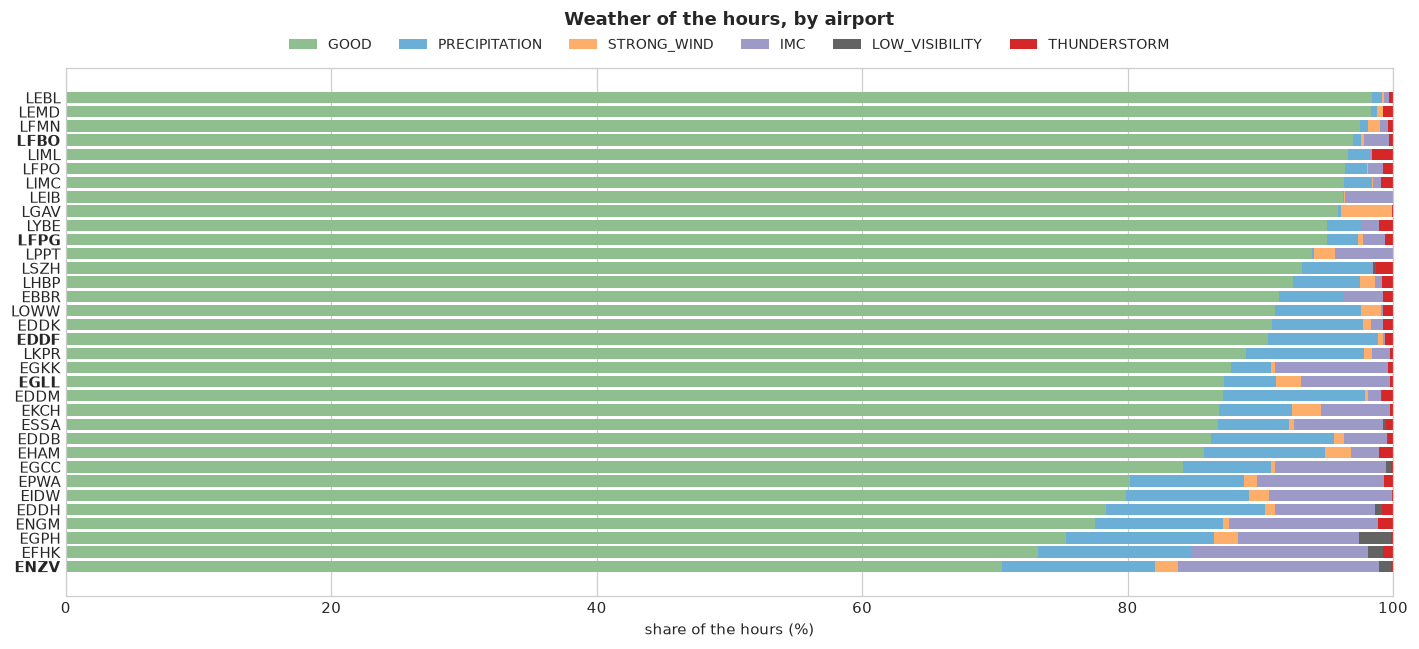

weather_category,GOOD,PRECIPITATION,STRONG_WIND,IMC,LOW_VISIBILITY,THUNDERSTORM
airport_icao,,,,,,
LFPG,95.0,2.3,0.4,1.7,0.0,0.6
LFBO,97.0,0.6,0.3,1.9,0.0,0.3
ENZV,70.5,11.5,1.8,15.1,0.9,0.1
EGLL,87.3,3.9,1.9,6.7,0.0,0.2
EDDF,90.6,8.3,0.4,0.2,0.0,0.6


In [3]:
share = (wh.groupby(["airport_icao", "weather_category"]).size().unstack(fill_value=0)
         .reindex(columns=CATEGORIES, fill_value=0))
share = share.div(share.sum(axis=1), axis=0) * 100
share = share.sort_values("GOOD")
fig, ax = plt.subplots(figsize=(13, 6))
left = np.zeros(len(share))
for cat in CATEGORIES:
    ax.barh(share.index, share[cat], left=left, color=CAT_COLORS[cat], label=cat)
    left += share[cat].values
for label in ax.get_yticklabels():
    if label.get_text() in FOCUS:
        label.set_fontweight("bold")
ax.set_xlabel("share of the hours (%)"); ax.set_xlim(0, 100)
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.08), fontsize=9, frameon=False)
ax.set_title("Weather of the hours, by airport", fontweight="bold", pad=28)
plt.tight_layout(); save(fig, "08_weather_conditions"); plt.show()
share.loc[[a for a in FOCUS if a in share.index]].round(1)

## 2. Arrival indicators by weather category

All airports with weather together, complete traffic hours. Additional time (indicator A) weighted by the measured
arrivals; level-off minutes and holdings (indicator B) weighted by all arrivals. Categories with fewer than
`MIN_MEASURED` measured arrivals are not shown for indicator A.

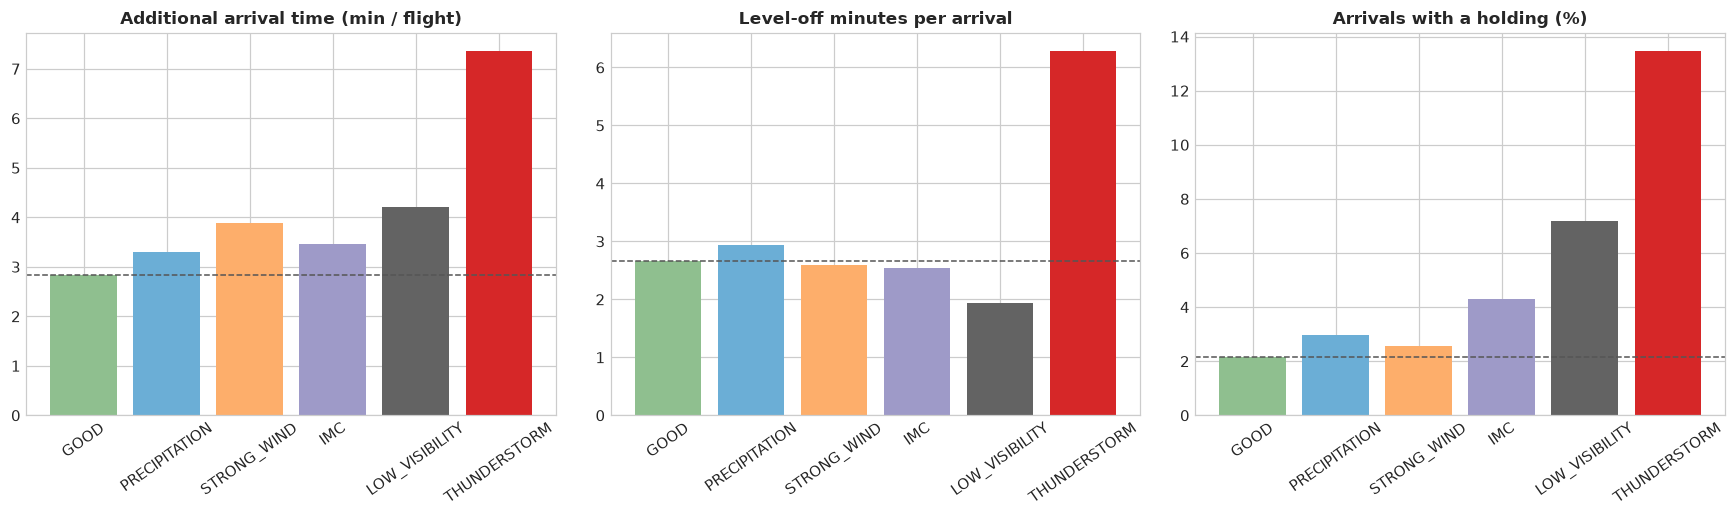

,hours,arrivals,measured,additional_min,level_min,pct_holding
weather_category,,,,,,
GOOD,37651.0,626201.0,442682.0,2.83,2.66,2.15
PRECIPITATION,2290.0,36259.0,24779.0,3.30,2.93,2.98
STRONG_WIND,356.0,7638.0,4911.0,3.89,2.60,2.56
IMC,1653.0,20851.0,13216.0,3.46,2.53,4.30
LOW_VISIBILITY,62.0,390.0,315.0,4.21,1.93,7.19
THUNDERSTORM,241.0,3396.0,2649.0,7.35,6.28,13.45


In [4]:
def pooled(df):
    return pd.Series({
        "hours": df["hours"].sum(), "arrivals": df["arrivals"].sum(), "measured": df["arrivals_measured"].sum(),
        "additional_min": np.average(df["avg_additional_min"].fillna(0), weights=df["arrivals_measured"])
                          if df["arrivals_measured"].sum() else np.nan,
        "level_min": np.average(df["avg_level_minutes"], weights=df["arrivals"]),
        "pct_holding": np.average(df["pct_with_holding"], weights=df["arrivals"])})

by_cat = impact.groupby("weather_category").apply(pooled).reindex(CATEGORIES).dropna(how="all")
by_cat.loc[by_cat["measured"] < MIN_MEASURED, "additional_min"] = np.nan
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, colname, title in zip(axes, ["additional_min", "level_min", "pct_holding"],
                              ["Additional arrival time (min / flight)", "Level-off minutes per arrival",
                               "Arrivals with a holding (%)"]):
    ax.bar(by_cat.index, by_cat[colname], color=[CAT_COLORS[c] for c in by_cat.index])
    good = by_cat.loc["GOOD", colname] if "GOOD" in by_cat.index else np.nan
    ax.axhline(good, color="#555555", ls="--", lw=1)
    ax.set_title(title, fontweight="bold", fontsize=11); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); save(fig, "09_weather_impact"); plt.show()
by_cat.round(2)

Per focus airport (rows with too few measured arrivals for indicator A are blank):

In [5]:
rows = []
for (apt, cat), d in impact[impact["airport_icao"].isin(FOCUS)].groupby(["airport_icao", "weather_category"]):
    r = pooled(d)
    if r["measured"] < MIN_MEASURED:
        r["additional_min"] = np.nan
    rows.append(r.rename((apt, cat)))
focus = pd.DataFrame(rows)
focus.index = pd.MultiIndex.from_tuples(focus.index, names=["airport", "weather"])
focus.round(2)

hours  arrivals  measured  additional_min  level_min  \
airport weather                                                                 
EDDF    GOOD             991.0   34098.0   27672.0            2.61       4.06   
        IMC                3.0     118.0     101.0            3.01       3.66   
        PRECIPITATION    100.0    3317.0    2909.0            3.28       4.80   
        STRONG_WIND        5.0     165.0     154.0            1.92       3.99   
        THUNDERSTORM       3.0      69.0      64.0             NaN       7.65   
EGLL    GOOD            1011.0   33494.0    4837.0            4.81       4.30   
        IMC               73.0    2435.0     220.0            7.45       5.08   
        PRECIPITATION     41.0    1283.0     133.0            6.30       5.61   
        STRONG_WIND       21.0     725.0      67.0             NaN       3.86   
        THUNDERSTORM       2.0      65.0       6.0             NaN       7.60   
ENZV    GOOD             773.0    3177.0      27.0             NaN       0.25   
        IMC              134.0     523.0       3.0             NaN       0.15   
        LOW_VISIBILITY     5.0      12.0       1.0             NaN       0.05   
        PRECIPITATION    109.0     401.0      17.0             NaN       0.18   
        STRONG_WIND       24.0     141.0       0.0             NaN       0.22   
        THUNDERSTORM       2.0       9.0       0.0             NaN       0.73   
LFBO    GOOD            1069.0    6031.0    4672.0            1.86       1.55   
        IMC               22.0     160.0     134.0            3.44       1.61   
        PRECIPITATION      8.0      36.0      27.0             NaN       3.04   
        STRONG_WIND        4.0      24.0      22.0             NaN       1.84   
        THUNDERSTORM       4.0      13.0      11.0             NaN       7.82   
LFPG    GOOD            1201.0   27439.0    7240.0            2.96       4.51   
        IMC               23.0     901.0     227.0            3.14       5.57   
        PRECIPITATION     30.0     829.0     182.0            3.81       5.71   
        STRONG_WIND        6.0     175.0      18.0             NaN       5.16   
        THUNDERSTORM       8.0     160.0      58.0             NaN      14.50   

                        pct_holding  
airport weather                      
EDDF    GOOD                    2.7  
        IMC                     4.2  
        PRECIPITATION           3.6  
        STRONG_WIND             1.2  
        THUNDERSTORM           21.7  
EGLL    GOOD                   11.9  
        IMC                    19.6  
        PRECIPITATION          20.1  
        STRONG_WIND             8.8  
        THUNDERSTORM           29.2  
ENZV    GOOD                    0.2  
        IMC                     0.4  
        LOW_VISIBILITY          0.0  
        PRECIPITATION           0.0  
        STRONG_WIND             0.7  
        THUNDERSTORM            0.0  
LFBO    GOOD                    0.6  
        IMC                     1.3  
        PRECIPITATION           5.6  
        STRONG_WIND             4.2  
        THUNDERSTORM           30.8  
LFPG    GOOD                    2.6  
        IMC                     4.4  
        PRECIPITATION           4.0  
        STRONG_WIND             2.9  
        THUNDERSTORM           35.6

## 3. Weather or demand?

A stormy hour can also be a busy hour. For the three hubs, the additional time by number of arrivals in the hour
(bins of 10), separately for the hours with good weather and the hours with adverse weather (any other category).
If the two curves stay close, the demand effect seen in notebook 05 is not a weather effect in disguise.

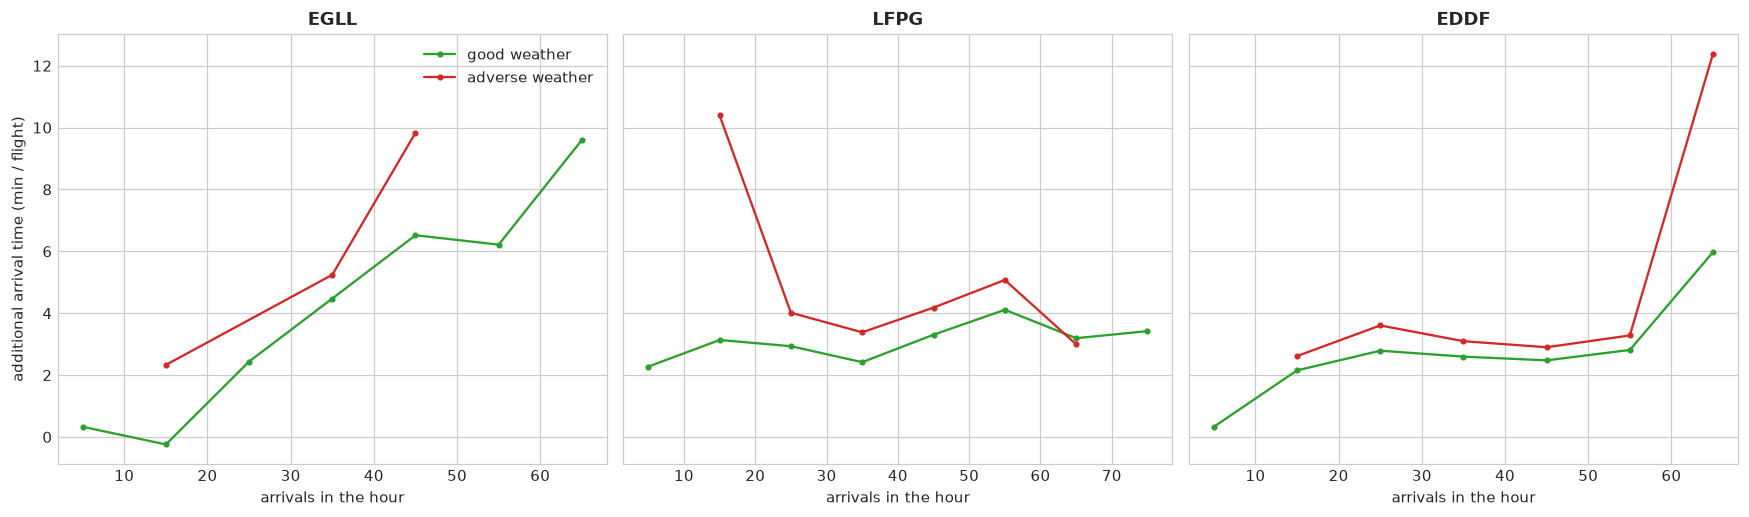

count  mean
airport_icao weather                     
EGLL         adverse weather     92  33.5
             good weather       777  33.2
LFPG         adverse weather     63  31.1
             good weather      1129  23.1
EDDF         adverse weather    111  33.1
             good weather       972  35.1

In [6]:
hw = hourly.merge(wh[["airport_icao", "weather_date", "weather_hour", "weather_category"]],
                  left_on=["airport_icao", "movement_date", "movement_hour"],
                  right_on=["airport_icao", "weather_date", "weather_hour"], how="inner")
hw = hw[hw["is_complete_hour"] & (hw["arrivals_measured"] > 0)].copy()
hw["weather"] = np.where(hw["weather_category"] == "GOOD", "good weather", "adverse weather")
hw["bin"] = (hw["arrivals"] // 10) * 10 + 5
hubs = [a for a in ["EGLL", "LFPG", "EDDF"] if a in set(hw["airport_icao"])]
fig, axes = plt.subplots(1, max(len(hubs), 1), figsize=(16, 4.8), sharey=True, squeeze=False)
for ax, apt in zip(axes[0], hubs):
    for label, colour in [("good weather", "#2ca02c"), ("adverse weather", "#d62728")]:
        d = hw[(hw["airport_icao"] == apt) & (hw["weather"] == label)]
        b = d.groupby("bin").apply(lambda z: pd.Series({
            "mean": np.average(z["avg_additional_min"], weights=z["arrivals_measured"]),
            "n": z["arrivals_measured"].sum()}))
        b = b[b["n"] >= 30] if not b.empty else b
        if not b.empty:
            ax.plot(b.index, b["mean"], "-o", ms=3, color=colour, label=label)
    ax.set_title(apt, fontweight="bold"); ax.set_xlabel("arrivals in the hour")
axes[0][0].set_ylabel("additional arrival time (min / flight)"); axes[0][0].legend()
plt.tight_layout(); save(fig, "10_weather_or_demand"); plt.show()
hw.groupby(["airport_icao", "weather"])["arrivals"].agg(["count", "mean"]).loc[hubs].round(1)

## 4. Does the weather improve the model?

The gradient-boosted trees of notebook 05 (same features, same hyperparameters, same temporal split), trained on the
same arrivals (airports with METAR) **without** and **with** the weather of the arrival hour, both compared with the
naive baseline (mean per airport and hour) on the same test days. The importance of the weather variables is only
published if the model with weather beats the naive baseline.

status: PASSED | MAE gain (min): -0.02 | R2 gain: -0.018 | weather share of the importance: 0.1358


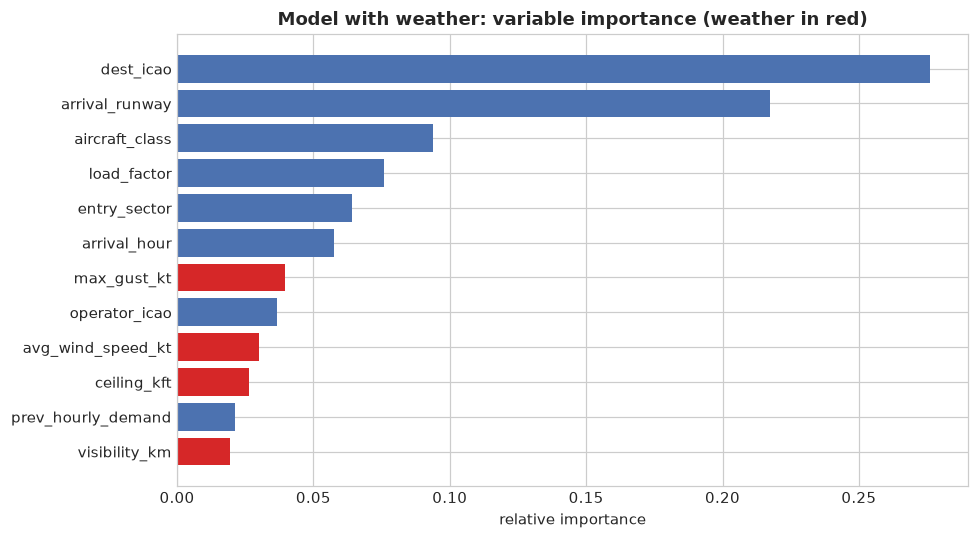

,model,n_features,airports,train_rows,test_rows,split_date,mae,rmse,r2,beats_naive_baseline
0,naive_baseline (mean per airport and hour),2,34,355757,132795,2026-07-14,2.726,3.945,0.098,None
1,gbt_without_weather,10,34,355757,132795,2026-07-14,2.638,3.847,0.143,True
2,gbt_with_weather,19,34,355757,132795,2026-07-14,2.658,3.887,0.125,True


In [7]:
wm = ml_report.get("weather", {})
print("status:", wm.get("status"), "| MAE gain (min):", wm.get("delta_mae_min"), "| R2 gain:", wm.get("delta_r2"),
      "| weather share of the importance:", wm.get("weather_importance_share"))
if not wfi.empty:
    weather_vars = {"avg_wind_speed_kt", "max_gust_kt", "visibility_km", "ceiling_kft", "thunderstorm",
                    "precipitation", "fog", "imc", "below_cat1"}
    top = wfi.sort_values("importance").tail(12)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top["variable"], top["importance"],
            color=["#d62728" if v in weather_vars else "#4c72b0" for v in top["variable"]])
    ax.set_xlabel("relative importance"); ax.set_title("Model with weather: variable importance (weather in red)",
                                                       fontweight="bold")
    plt.tight_layout(); save(fig, "11_weather_model"); plt.show()
comparison.drop(columns=["_ml_built_at_utc"], errors="ignore").round(3)

## 5. Reading the figures

Run `prod-17` (58 days, 34 airports, 47,281 airport hours with METAR, complete traffic hours).

- **Figure 08.** Summer weather is mostly good: 89 % of the airport hours, from 70 % at Stavanger (15 % IMC) to
  98 % at Barcelona. Thunderstorms are rare (268 airport hours).
- **Figure 09.** Every adverse category raises the additional time: 2.8 min in good weather, 3.3 with precipitation,
  3.5 in IMC, 3.9 with strong wind, 4.2 below CAT I and 7.4 min in thunderstorm hours, which also more than double
  the level flight (6.3 vs 2.7 min) and multiply the holdings by six (13.4 vs 2.2 %). Low visibility raises the
  holdings (7.2 %) but not the level flight.
- **Figure 10.** Weather does not explain away the demand effect. At Heathrow, good and adverse hours have the same
  mean demand (33 arrivals) and both curves rise with it, adverse weather adding 0.7 to 3.3 min on top. At Paris-CDG,
  adverse hours are busier (31 vs 23 arrivals), so part of their extra time is demand.
- **Figure 11.** The weather variables take 13.6 % of the importance (gusts and mean wind first), but the model with
  weather does not beat the model without it on the test days (MAE 2.658 vs 2.638 min, R² 0.125 vs 0.143): bad-weather
  hours are few and partly absorbed by the airport, runway and demand variables.

These are associations at the destination airport only (no en-route weather, no winds aloft), over one summer.